# Fase 3 — Aprendizaje, pronóstico y evaluación

Material de apoyo elaborado con asistencia de IA. El grupo debe revisar y asumir las decisiones metodológicas e interpretar los resultados antes de entregar. No se fabrican observaciones individuales.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'protocolo.json').exists())
sys.path.insert(0, str(ROOT / 'src'))
from common import OUT, PROTOCOL
from data_prep import main as preparar
if not (ROOT / 'data/processed/serie_mensual.csv').exists():
    _ = preparar()
pd.set_option('display.max_columns', 15)
pd.set_option('display.max_colwidth', 100)
display(Markdown('**Protocolo temporal:** desarrollo 2016–2022; calibración 2023; prueba 2024.'))


**Protocolo temporal:** desarrollo 2016–2022; calibración 2023; prueba 2024.

## Diseño experimental y grilla

Dos referencias y cuatro familias aprendidas: Ridge, Random Forest, SVR y ETS. Las configuraciones se comparan en cuatro cortes anuales 2019–2022. Cada corte pronostica doce meses desde un único origen. La búsqueda no incluye prueba ni calibración.

In [2]:
from models import specifications, FEATURES
display(pd.DataFrame(specifications()))
display(FEATURES)
from phase3 import main as modelar
resultado = modelar()

,familia,parametros,id
0,Referencia estacional,{},M00
1,Referencia media12,{},M01
2,Ridge,{'alpha': 0.1},M02
3,Ridge,{'alpha': 1.0},M03
4,Ridge,{'alpha': 10.0},M04
5,Ridge,{'alpha': 100.0},M05
6,Random Forest,"{'max_depth': 3, 'min_samples_leaf': 2, 'n_estimators': 250}",M06
7,Random Forest,"{'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 250}",M07
8,Random Forest,"{'max_depth': 3, 'min_samples_leaf': 10, 'n_estimators': 250}",M08
9,Random Forest,"{'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 250}",M09


['rezago_1',
 'rezago_2',
 'rezago_3',
 'rezago_6',
 'rezago_12',
 'media_previa_3',
 'media_previa_12',
 'sin_mes',
 'cos_mes',
 'dias_mes']

Fase 3: resultados reproducibles existentes; no se repite seleccion ni prueba.


En una reproducción con resultados idénticos se reutiliza el cálculo registrado. Desde una carpeta limpia, la misma llamada reconstruye la búsqueda y evaluación. El archivo `seleccion_congelada_antes_prueba.json` registra el criterio y los parámetros previos a evaluar 2024.

In [3]:
display(pd.read_csv(OUT / 'tables/mejores_por_familia_CV.csv'))
display(json.loads((OUT / 'seleccion_congelada_antes_prueba.json').read_text(encoding='utf-8')))

,id,familia,MAE_CV,RMSE_CV,MAE_CV_desvio_entre_anos,parametros
0,M13,SVR,24.078191,33.380462,9.648262,"{""C"": 1.0, ""epsilon"": 15.0, ""gamma"": ""scale""}"
1,M05,Ridge,26.235647,35.152028,11.340234,"{""alpha"": 100.0}"
2,M06,Random Forest,30.438621,40.771103,15.269147,"{""max_depth"": 3, ""min_samples_leaf"": 2, ""n_estimators"": 250}"
3,M20,ETS,30.996358,42.005880,17.797085,"{""trend"": ""add"", ""seasonal"": null, ""damped_trend"": true}"
4,M01,Referencia media12,31.465278,42.319080,18.231230,{}
5,M00,Referencia estacional,37.229167,49.074985,17.494229,{}


{'seleccion': {'familia': 'SVR',
  'parametros': {'C': 1.0, 'epsilon': 15.0, 'gamma': 'scale'},
  'id': 'M13'},
 'mejor_aprendido': {'familia': 'SVR',
  'parametros': {'C': 1.0, 'epsilon': 15.0, 'gamma': 'scale'},
  'id': 'M13'},
 'criterio': 'Menor MAE medio de las 48 predicciones de validacion; empate: menor complejidad segun orden de especificaciones',
 'huella_datos_protocolo': 'a5c2574b18d3fa086a04e99fe847605ecd322f4ea160578d06eb5fe550e4de73-021ce46a60a0a385e557bbd6785ef48d07e90d22b9af7a257b4115d702d5fd8e',
 'ranking': [{'id': 'M13',
   'familia': 'SVR',
   'MAE_CV': 24.078190633876588,
   'RMSE_CV': 33.380461596942325,
   'MAE_CV_desvio_entre_anos': 9.64826242980969,
   'parametros': '{"C": 1.0, "epsilon": 15.0, "gamma": "scale"}'},
  {'id': 'M05',
   'familia': 'Ridge',
   'MAE_CV': 26.23564657983521,
   'RMSE_CV': 35.15202848138174,
   'MAE_CV_desvio_entre_anos': 11.340234403365104,
   'parametros': '{"alpha": 100.0}'},
  {'id': 'M06',
   'familia': 'Random Forest',
   'MAE_CV'

## Qué aprendió cada modelo

Se informa ajuste, validación y prueba. El ajuste usa un paso con antecedentes reales; validación y prueba son doce pasos. Random Forest ajusta más el entrenamiento, pero generaliza peor. SVR fue elegido por validación, aunque Ridge obtenga después un MAE de prueba ligeramente menor.

,id,familia,MAE_CV,RMSE_CV,parametros,MAE_train,RMSE_train,MAE_test,RMSE_test,MAPE,R2,MASE,seleccionado_por_CV
0,M13,SVR,24.078191,33.380462,"{""C"": 1.0, ""epsilon"": 15.0, ""gamma"": ""scale""}",23.055427,30.782188,10.874336,15.318487,7.129525,-0.476663,0.279940,True
1,M05,Ridge,26.235647,35.152028,"{""alpha"": 100.0}",18.360926,24.210344,10.668414,13.707069,7.233414,-0.182330,0.274639,False
2,M06,Random Forest,30.438621,40.771103,"{""max_depth"": 3, ""min_samples_leaf"": 2, ""n_estimators"": 250}",12.594941,16.309418,32.610978,34.904577,23.774541,-6.666803,0.839510,False
3,M20,ETS,30.996358,42.005880,"{""trend"": ""add"", ""seasonal"": null, ""damped_trend"": true}",20.189661,25.307481,31.304400,33.695482,22.865885,-6.144846,0.805875,False
4,M01,Referencia media12,31.465278,42.319080,{},26.460317,32.819295,28.583333,31.239665,19.485440,-5.141328,0.735826,False
5,M00,Referencia estacional,37.229167,49.074985,{},38.845238,49.560809,36.583333,43.151864,25.651824,-10.717869,0.941771,False


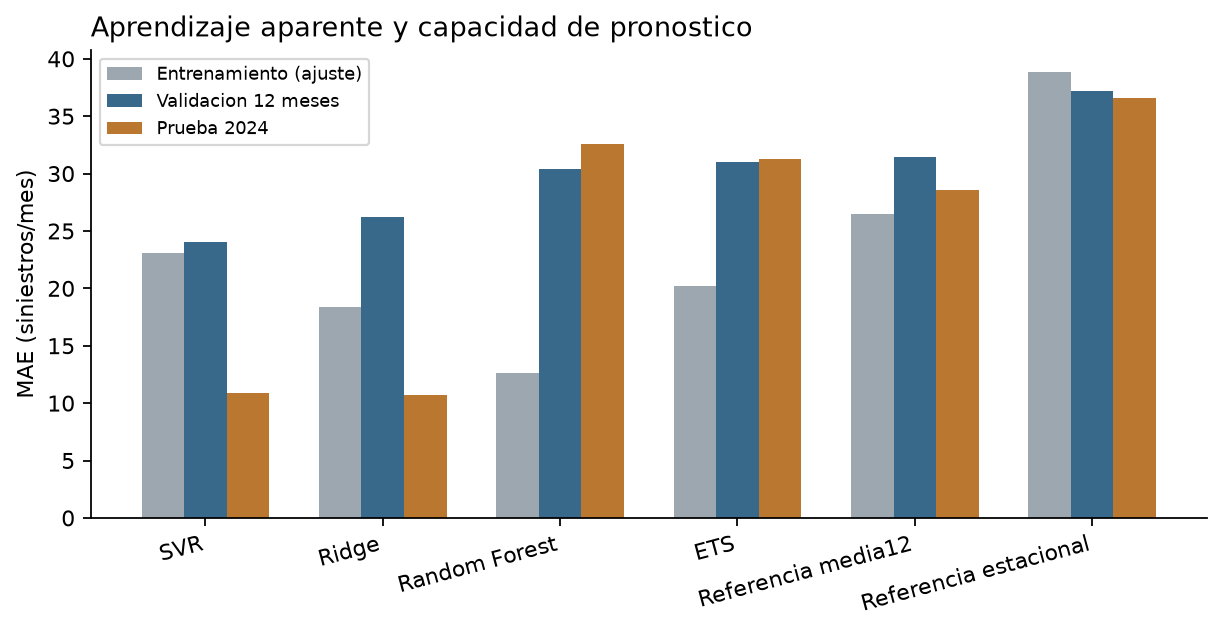

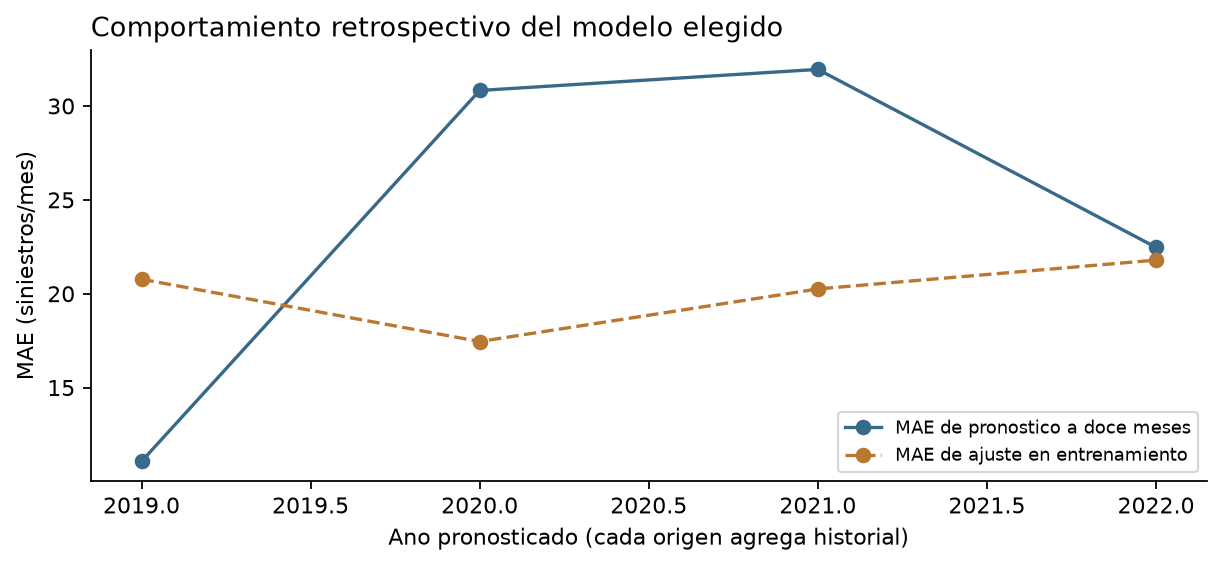

In [4]:
comparacion = pd.read_csv(OUT / 'tables/comparacion_train_CV_test.csv')
display(comparacion)
display(Image(filename=str(OUT / 'figures/f3_01_comparacion.png')))
display(Image(filename=str(OUT / 'figures/f3_04_cortes.png')))

## Prueba final de 2024

MAE, RMSE, MAPE y R² se calculan sin redondear las predicciones. MAPE no es un porcentaje de exactitud. R² negativo se comunica explícitamente: la mejora frente a las referencias operativas no equivale a explicar bien las fluctuaciones de 2024.

,id,familia,MAE,RMSE,MAPE,R2,sesgo,total_real,total_predicho,error_total,MASE
0,M13,SVR,10.874336,15.318487,7.129525,-0.476663,-8.886667,1709.0,1602.359991,-106.640009,0.279940
1,M05,Ridge,10.668414,13.707069,7.233414,-0.182330,-2.082254,1709.0,1684.012948,-24.987052,0.274639
2,M06,Random Forest,32.610978,34.904577,23.774541,-6.666803,32.610978,1709.0,2100.331735,391.331735,0.839510
3,M20,ETS,31.304400,33.695482,22.865885,-6.144846,31.248613,1709.0,2083.983355,374.983355,0.805875
4,M01,Referencia media12,28.583333,31.239665,19.485440,-5.141328,-28.583333,1709.0,1366.000000,-343.000000,0.735826
5,M00,Referencia estacional,36.583333,43.151864,25.651824,-10.717869,-28.583333,1709.0,1366.000000,-343.000000,0.941771


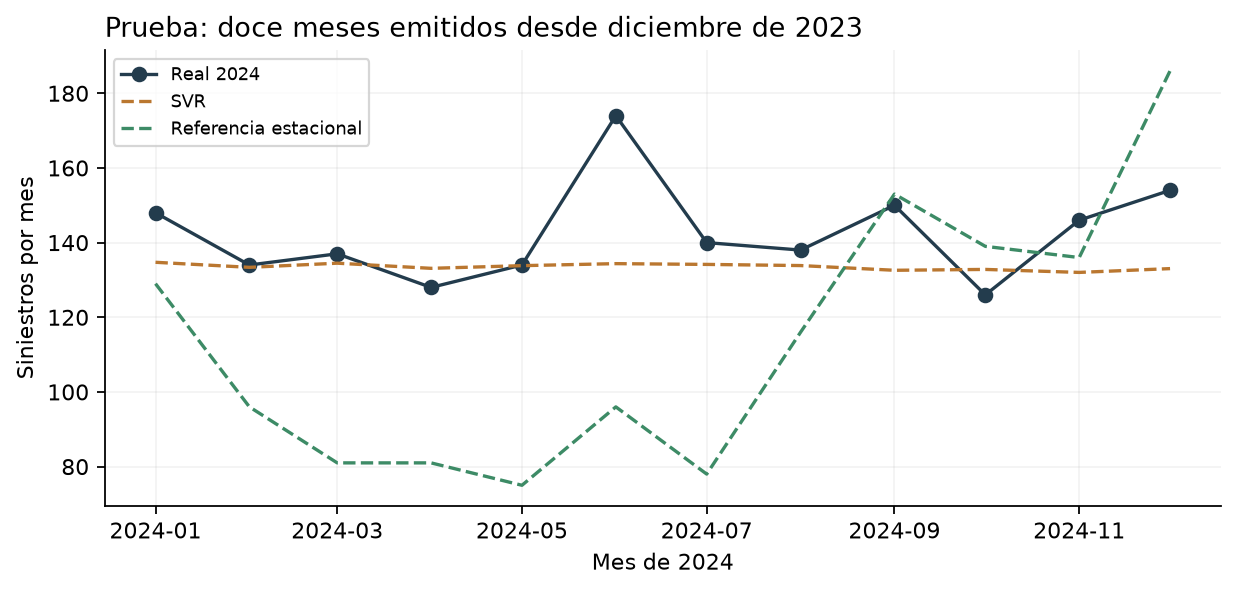

,id,familia,horizonte,fecha,real,prediccion,error,error_absoluto
0,M13,SVR,6,2024-06-01,174.0,134.365558,-39.634442,39.634442
1,M13,SVR,12,2024-12-01,154.0,133.035101,-20.964899,20.964899
2,M13,SVR,9,2024-09-01,150.0,132.587385,-17.412615,17.412615
3,M13,SVR,11,2024-11-01,146.0,132.017761,-13.982239,13.982239
4,M13,SVR,1,2024-01-01,148.0,134.728165,-13.271835,13.271835


In [5]:
display(pd.read_csv(OUT / 'tables/metricas_prueba_2024.csv'))
display(Image(filename=str(OUT / 'figures/f3_02_prueba.png')))
display(pd.read_csv(OUT / 'tables/cinco_errores_mayores_2024.csv'))

Las predicciones SVR de prueba son casi planas (aproximadamente 132–135 siniestros/mes), mientras los valores reales varían entre 126 y 174. La generalización lograda es principalmente una estimación del nivel; no anticipa los picos.

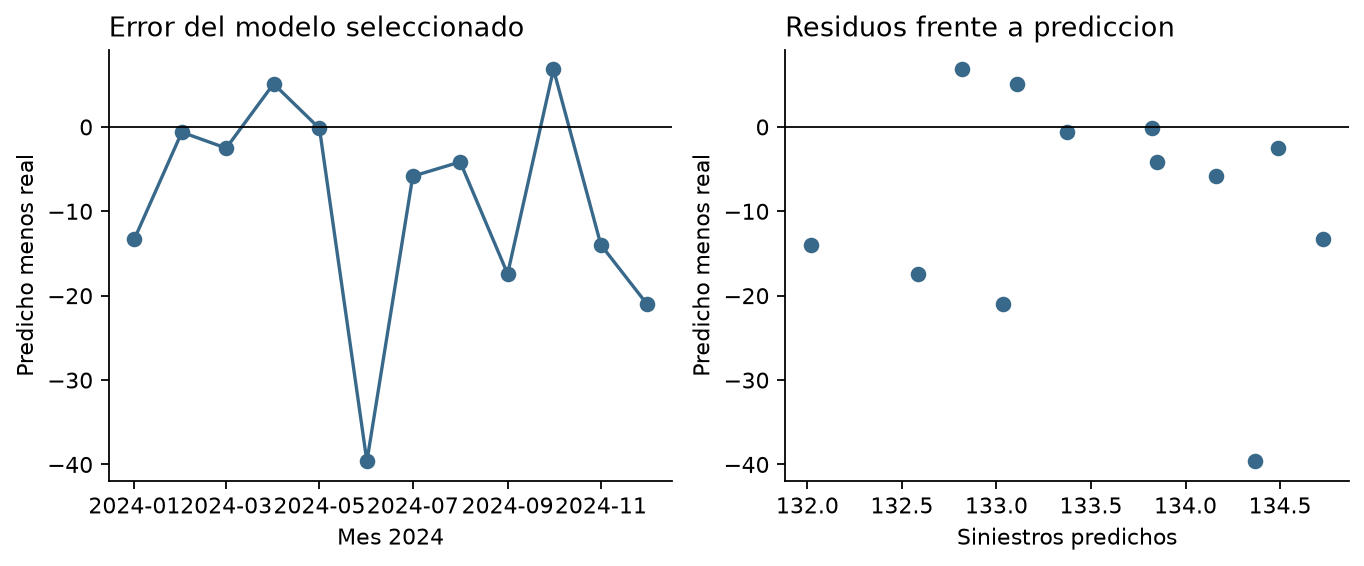

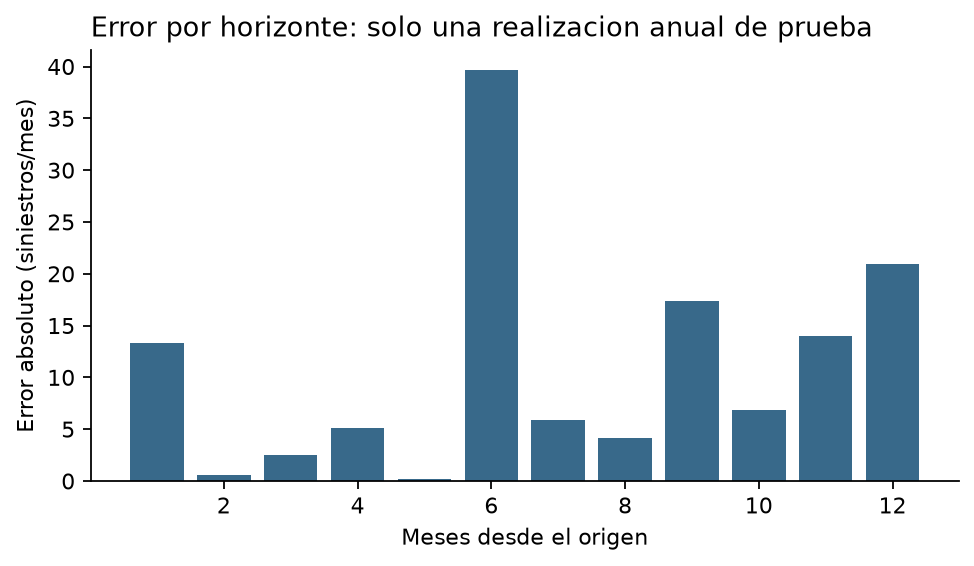

In [6]:
display(Image(filename=str(OUT / 'figures/f3_03_residuos.png')))
display(Image(filename=str(OUT / 'figures/f3_07_horizonte.png')))

## Interpretación sin usar prueba para seleccionar

La perturbación de entradas se realiza en validación y ejecuta la recursión completa. Cambios pequeños o negativos no prueban una influencia causal. La baja sensibilidad del SVR es coherente con su fuerte regularización y perfil casi constante.

,variable,aumento_MAE_medio,desvio,metodo
0,rezago_1,0.019124,0.140895,"Perturbacion marginal de entradas en recursion; validacion, no prueba"
1,rezago_2,-0.008136,0.125351,"Perturbacion marginal de entradas en recursion; validacion, no prueba"
2,rezago_3,0.011938,0.149140,"Perturbacion marginal de entradas en recursion; validacion, no prueba"
3,rezago_6,-0.006489,0.094465,"Perturbacion marginal de entradas en recursion; validacion, no prueba"
4,rezago_12,-0.058539,0.300890,"Perturbacion marginal de entradas en recursion; validacion, no prueba"
5,media_previa_3,-0.022642,0.144897,"Perturbacion marginal de entradas en recursion; validacion, no prueba"
6,media_previa_12,0.076699,0.290603,"Perturbacion marginal de entradas en recursion; validacion, no prueba"
7,sin_mes,-0.025265,0.099528,"Perturbacion marginal de entradas en recursion; validacion, no prueba"
8,cos_mes,0.034376,0.225703,"Perturbacion marginal de entradas en recursion; validacion, no prueba"
9,dias_mes,0.056861,0.147169,"Perturbacion marginal de entradas en recursion; validacion, no prueba"


,variable,coeficiente_por_desvio_X
0,rezago_1,6.994604
1,rezago_2,2.653631
2,rezago_3,1.436617
3,rezago_6,0.830128
4,rezago_12,-2.735960
5,media_previa_3,4.141758
6,media_previa_12,1.854438
7,sin_mes,-2.133629
8,cos_mes,-0.465651
9,dias_mes,2.844315


,variable,importancia_impureza
0,rezago_1,0.443773
1,rezago_2,0.037530
2,rezago_3,0.028937
3,rezago_6,0.030532
4,rezago_12,0.024371
5,media_previa_3,0.326192
6,media_previa_12,0.032480
7,sin_mes,0.036461
8,cos_mes,0.033101
9,dias_mes,0.006622


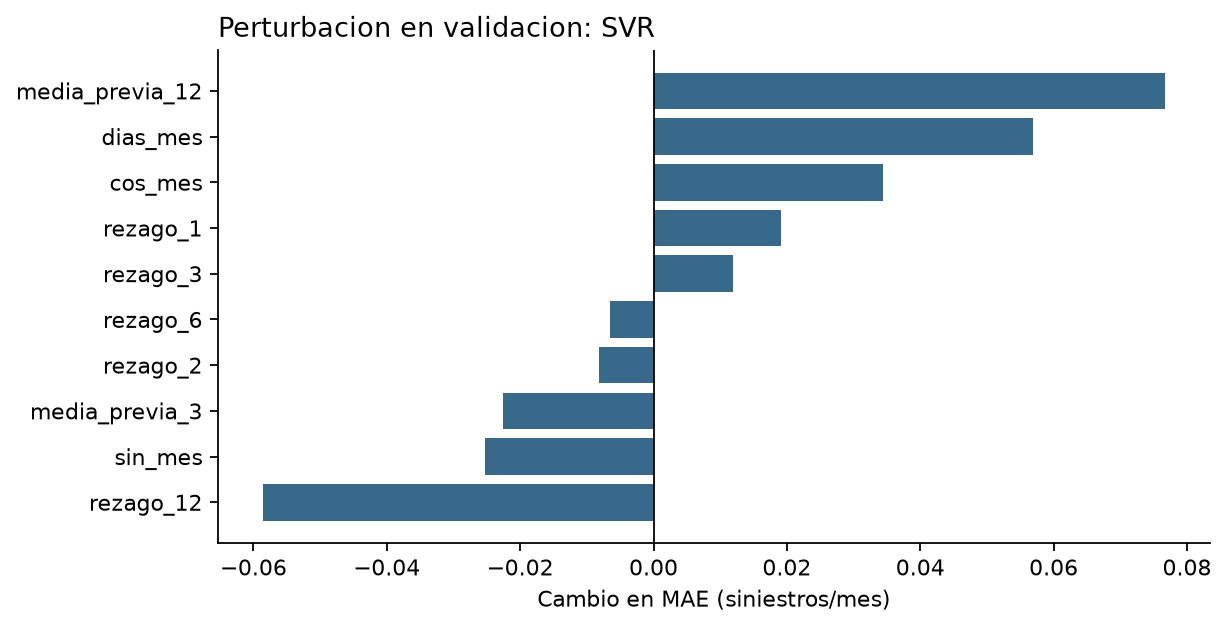

In [7]:
display(pd.read_csv(OUT / 'tables/importancia_perturbacion_CV.csv'))
display(pd.read_csv(OUT / 'tables/coeficientes_Ridge.csv'))
display(pd.read_csv(OUT / 'tables/importancia_RF.csv'))
display(Image(filename=str(OUT / 'figures/f3_05_importancia.png')))

## Bandas y proyección con corte declarado

El radio empírico se obtiene con errores de 2023 tras fijar el modelo. La dependencia temporal impide garantizar cobertura del 90%. El total anual no recibe un intervalo formal basado en un único bloque de calibración. La proyección de 2025 usa corte diciembre 2024; no se etiqueta como pronóstico actual de 2027.

{'ano': 2023,
 'n': 12,
 'radio_banda': 61.273135657744575,
 'orden_residuo': 12,
 'MAE': 34.189150761645344,
 'cobertura_observada_2024': 1.0,
 'advertencia': 'Banda orientativa: errores temporalmente dependientes y no intercambiables garantizados.'}

,fecha,prediccion,banda_inferior,banda_superior,origen,nota
0,2025-01-01,136.345665,75.072529,197.618801,2024-12-01,Proyeccion retrospectiva de 2025; bandas empiricas sin cobertura garantizada
1,2025-02-01,134.439312,73.166176,195.712447,2024-12-01,Proyeccion retrospectiva de 2025; bandas empiricas sin cobertura garantizada
2,2025-03-01,136.486495,75.213359,197.759630,2024-12-01,Proyeccion retrospectiva de 2025; bandas empiricas sin cobertura garantizada
3,2025-04-01,135.191203,73.918068,196.464339,2024-12-01,Proyeccion retrospectiva de 2025; bandas empiricas sin cobertura garantizada
4,2025-05-01,136.662222,75.389087,197.935358,2024-12-01,Proyeccion retrospectiva de 2025; bandas empiricas sin cobertura garantizada
5,2025-06-01,136.236355,74.963219,197.509490,2024-12-01,Proyeccion retrospectiva de 2025; bandas empiricas sin cobertura garantizada
6,2025-07-01,136.305600,75.032464,197.578736,2024-12-01,Proyeccion retrospectiva de 2025; bandas empiricas sin cobertura garantizada
7,2025-08-01,135.815889,74.542753,197.089025,2024-12-01,Proyeccion retrospectiva de 2025; bandas empiricas sin cobertura garantizada
8,2025-09-01,134.566508,73.293372,195.839644,2024-12-01,Proyeccion retrospectiva de 2025; bandas empiricas sin cobertura garantizada
9,2025-10-01,134.645550,73.372414,195.918685,2024-12-01,Proyeccion retrospectiva de 2025; bandas empiricas sin cobertura garantizada


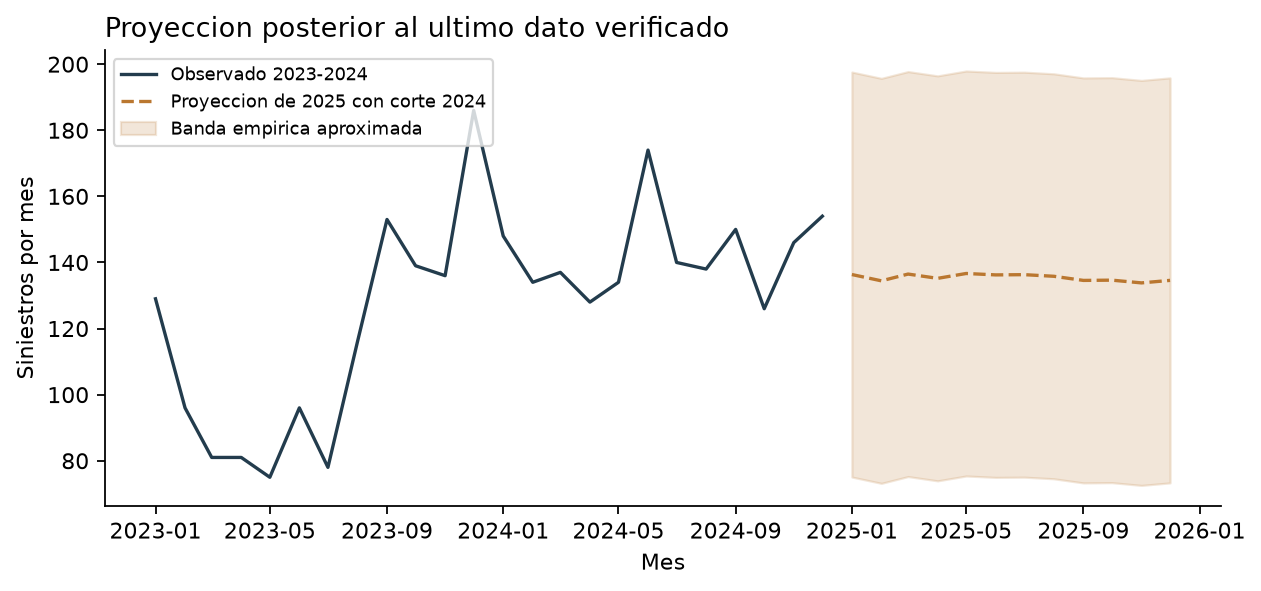

In [8]:
display(resultado['calibracion'])
display(pd.read_csv(OUT / 'tables/pronostico_2025_corte_2024.csv'))
display(Image(filename=str(OUT / 'figures/f3_06_proyeccion.png')))

## Modelo guardado e inferencia reproducible

Se conservan por separado el modelo evaluado en 2024 y el reajustado con todos los datos. El ejemplo siguiente reproduce la proyección guardada. El script `src/inference.py` también acepta un CSV mensual nuevo validado, manteniendo la especificación elegida.

In [9]:
import joblib
from models import forecast
artefacto = joblib.load(OUT / 'models/modelo_pronostico.joblib')
display(forecast(artefacto['model'], 12).rename('prediccion').to_frame())
print('Origen:', artefacto['origen'])
print('Selección por validación:', artefacto['selected_spec'])

,prediccion
2025-01-01,136.345665
2025-02-01,134.439312
2025-03-01,136.486495
2025-04-01,135.191203
2025-05-01,136.662222
2025-06-01,136.236355
2025-07-01,136.305600
2025-08-01,135.815889
2025-09-01,134.566508
2025-10-01,134.645550


Origen: 2024-12-01
Selección por validación: {'familia': 'SVR', 'parametros': {'C': 1.0, 'epsilon': 15.0, 'gamma': 'scale'}, 'id': 'M13'}


## Conclusión

SVR reduce errores frente a las dos referencias en 2024, pero el R² negativo y el perfil casi plano limitan su utilidad. No se modifica al ganador tras consultar prueba. Para mejorar o pronosticar 2027 se necesitan datos comparables recientes, nueva validación y factores externos realmente disponibles al emitir el pronóstico. El grupo debe revisar estas decisiones e interpretaciones según la consigna.